In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd

In [11]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit

AA = "ACDEFGHIKLMNPQRSTVWYX" 
aa_to_idx = {a: i for i, a in enumerate(AA)}
X_IDX = aa_to_idx["X"]

def encode_seq(seq):
    idx = torch.tensor([aa_to_idx.get(a, X_IDX) for a in seq.upper()],
                       dtype=torch.long)
    return F.one_hot(idx, num_classes=len(AA)).float()


ss_to_idx = {"H": 0, "E": 1, "C": 2}
def encode_labels(s):
    return torch.tensor([ss_to_idx[c] for c in s], dtype=torch.long)

def windows(onehot, half=7):
    padded = F.pad(onehot, (0, 0, half, half))        # pad along the length dimension
    w = padded.unfold(0, 2 * half + 1, 1)             # (L, 21, 15)
    return w.permute(0, 2, 1).reshape(len(onehot), -1)  # (L, 15*21)

df = pd.read_csv("./selected_proteins.csv")
df["chain_key"] = df["pdb_id"] + "_" + df["chain"].astype(str)

groups = df["chain_key"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=groups))
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=42)
tr_idx, val_idx = next(gss_val.split(train_df, groups=train_df["chain_key"]))
val_df = train_df.iloc[val_idx]
train_df = train_df.iloc[tr_idx]

def build(split_df):
    X = torch.cat([windows(encode_seq(s)) for s in split_df["sequence"]])
    y = torch.cat([encode_labels(s) for s in split_df["structure"]])
    return TensorDataset(X, y)

train_dataset, val_dataset, test_dataset = build(train_df), build(val_df), build(test_df)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)
print(len(train_dataset), len(val_dataset), len(test_dataset))

1305365 186500 372048


epoch   1 | train loss 0.8759 | val loss 0.8719 | val Q3 0.5983
epoch   2 | train loss 0.8717 | val loss 0.8710 | val Q3 0.6045
epoch   3 | train loss 0.8711 | val loss 0.8697 | val Q3 0.6017
epoch   4 | train loss 0.8706 | val loss 0.8701 | val Q3 0.6076
epoch   5 | train loss 0.8703 | val loss 0.8685 | val Q3 0.6010
epoch   6 | train loss 0.8703 | val loss 0.8690 | val Q3 0.6027
epoch   7 | train loss 0.8702 | val loss 0.8720 | val Q3 0.5953
epoch   8 | train loss 0.8700 | val loss 0.8694 | val Q3 0.6015
epoch   9 | train loss 0.8700 | val loss 0.8678 | val Q3 0.6042
epoch  10 | train loss 0.8700 | val loss 0.8698 | val Q3 0.6037
epoch  11 | train loss 0.8699 | val loss 0.8687 | val Q3 0.6033
epoch  12 | train loss 0.8699 | val loss 0.8690 | val Q3 0.6010
epoch  13 | train loss 0.8699 | val loss 0.8685 | val Q3 0.6058
epoch  14 | train loss 0.8699 | val loss 0.8680 | val Q3 0.6020
epoch  15 | train loss 0.8699 | val loss 0.8689 | val Q3 0.6038
epoch  16 | train loss 0.8696 | val loss

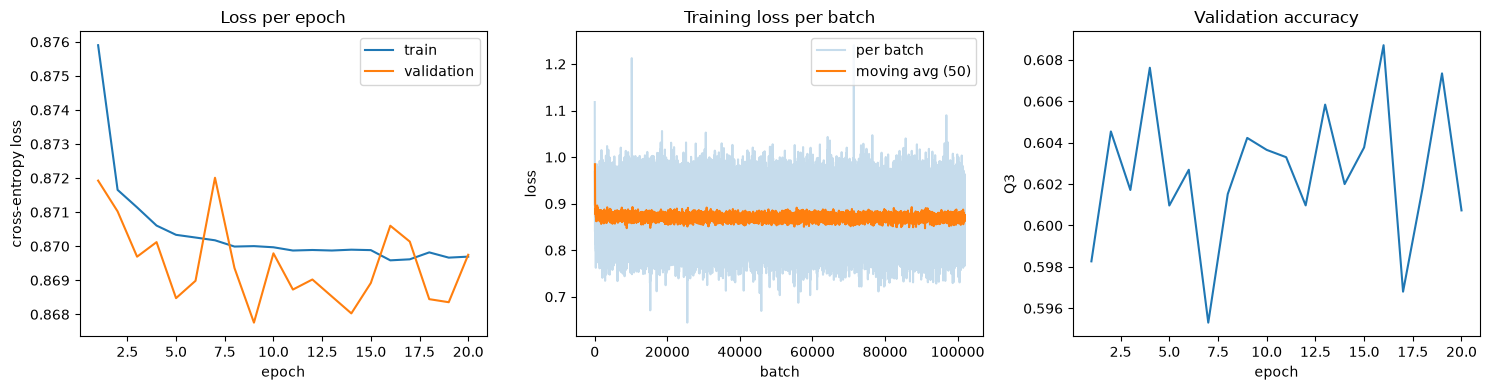

Q3 accuracy: 0.6013
class  precision    recall        f1   support
H          0.657     0.588     0.620    142462
E          0.469     0.609     0.530     87584
C          0.663     0.610     0.635    142002

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H        83732   31693   27037
E        17231   53359   16994
C        26568   28812   86622


(0.6013014316558838,
 tensor([0.6566, 0.4686, 0.6630]),
 tensor([0.5877, 0.6092, 0.6100]))

In [13]:
import torch, torch.nn as nn
from softmax_ss import SoftmaxRegression, train, plot_history, evaluate, report

counts = torch.bincount(train_dataset.tensors[1]).float()
class_weight = counts.sum() / (len(counts) * counts)    # balanced weights, training labels only

model = SoftmaxRegression(n_features=315)
history = train(model, train_loader, val_loader, epochs=20, lr=1e-2, class_weight=class_weight)
plot_history(history)

_, pred, true = evaluate(model, test_loader, nn.CrossEntropyLoss())
report(pred, true)

epoch   1 | train loss 0.9026 | val loss 0.8519 | val Q3 0.5983
epoch   2 | train loss 0.8144 | val loss 0.7764 | val Q3 0.6560
epoch   3 | train loss 0.7893 | val loss 0.7629 | val Q3 0.6612
epoch   4 | train loss 0.7768 | val loss 0.7542 | val Q3 0.6663
epoch   5 | train loss 0.7695 | val loss 0.7589 | val Q3 0.6767
epoch   6 | train loss 0.7648 | val loss 0.7470 | val Q3 0.6762
epoch   7 | train loss 0.7609 | val loss 0.7441 | val Q3 0.6708
epoch   8 | train loss 0.7561 | val loss 0.7391 | val Q3 0.6737
epoch   9 | train loss 0.7538 | val loss 0.7461 | val Q3 0.6645
epoch  10 | train loss 0.7529 | val loss 0.7401 | val Q3 0.6677
epoch  11 | train loss 0.7501 | val loss 0.7370 | val Q3 0.6803
epoch  12 | train loss 0.7479 | val loss 0.7343 | val Q3 0.6805
epoch  13 | train loss 0.7468 | val loss 0.7321 | val Q3 0.6772
epoch  14 | train loss 0.7438 | val loss 0.7316 | val Q3 0.6779
epoch  15 | train loss 0.7459 | val loss 0.7306 | val Q3 0.6773
epoch  16 | train loss 0.7438 | val loss

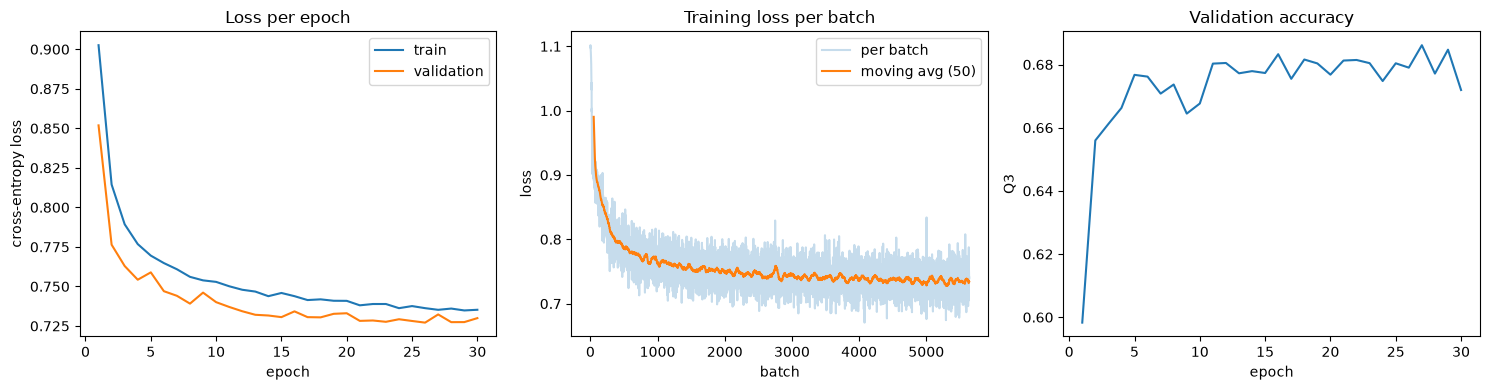

Q3 accuracy: 0.6806
class  precision    recall        f1   support
H          0.765     0.701     0.732    142462
E          0.554     0.698     0.618     87584
C          0.703     0.649     0.675    142002

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H        99920   20180   22362
E         9860   61126   16598
C        20782   29045   92175


(0.6806138157844543,
 tensor([0.7653, 0.5539, 0.7029]),
 tensor([0.7014, 0.6979, 0.6491]))

In [14]:
from cnn_ss import *
from softmax_ss import plot_history, report

cnn_train = DataLoader(ChainDataset(train_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=True, collate_fn=collate)
cnn_val   = DataLoader(ChainDataset(val_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=False, collate_fn=collate)
cnn_test  = DataLoader(ChainDataset(test_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=False, collate_fn=collate)

counts = torch.bincount(torch.cat([encode_labels(s) for s in train_df["structure"]])).float()
class_weight = counts.sum() / (len(counts) * counts)

cnn = CNN1D()
history = train_cnn(cnn, cnn_train, cnn_val, epochs=30, lr=1e-3, class_weight=class_weight)
plot_history(history)

_, pred, true = evaluate_cnn(cnn, cnn_test, nn.CrossEntropyLoss(ignore_index=PAD_LABEL))
report(pred, true)